In [1]:
import matplotlib.pyplot as plt

from softpotato.geometry import PlanarGeometry
from softpotato.reactions import (
    ButlerVolmer,
    ElectrochemicalStep,
    Mechanism,
    Species,
)
from softpotato.techniques import CyclicVoltammetry, simulate

# Constants
D = 1e-9  # m^2/s
cR_bulk = 1  # mol/m^3 (1 mM)
cO_bulk = 0  # mol/m^3
cP_bulk = 0  # mol/m^3
area = 1e-4  # m^2 (1 cm^2)
E0_1 = 0  # V
E0_2 = 0.3  # V
n_rxn = 1
k0 = 1  # m/s
alpha = 0.5

# Define CV
cv = CyclicVoltammetry(E_start=-0.4, E_vertex1=0.7, E_vertex2=-0.4, scan_rate=0.1)

# Species definition
red = Species(
    name="Red",
    diffusivity=D,
    bulk_concentration=cR_bulk,
    standard_potential=E0_1,
    n_electrons=-n_rxn,
)

ox = Species(
    name="Ox",
    diffusivity=D,
    bulk_concentration=cO_bulk,
    standard_potential=E0_1,
    n_electrons=n_rxn,
)

prod = Species(
    name="Prod",
    diffusivity=D,
    bulk_concentration=cP_bulk,
    standard_potential=E0_2,
    n_electrons=-n_rxn,
)

ee_mech = Mechanism(
    species=[ox, red, prod],
    electrochemical_steps=[
        ElectrochemicalStep(
            ox=ox, red=red, kinetics=ButlerVolmer(k0=k0, alpha=alpha, E0=E0_1, n=n_rxn)
        ),
        ElectrochemicalStep(
            ox=ox, red=prod, kinetics=ButlerVolmer(k0=k0, alpha=alpha, E0=E0_2, n=n_rxn)
        ),
        ElectrochemicalStep(
            ox=prod,
            red=red,
            kinetics=ButlerVolmer(k0=k0, alpha=alpha, E0=E0_1, n=n_rxn),
        ),
    ],
)

# Set planar geometry
geometry = PlanarGeometry(area)

# Run simulation
# The mechanism is written in the order of the reaction: Ox + e- <-> Red
sim = simulate(technique=cv, mechanism=ee_mech, geometry=geometry)

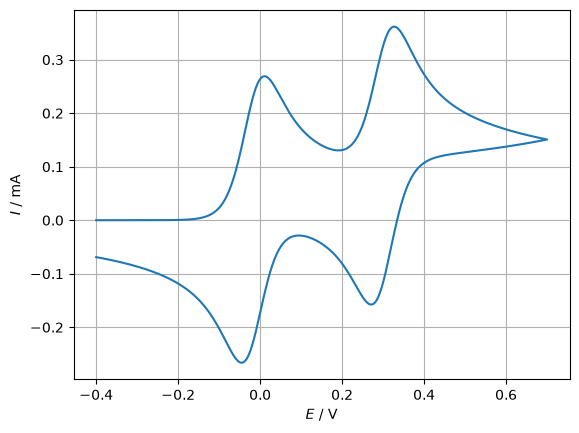

In [2]:
plt.figure()
plt.plot(sim.potential, sim.current * 1e3)
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / mA")
plt.grid()
plt.show()

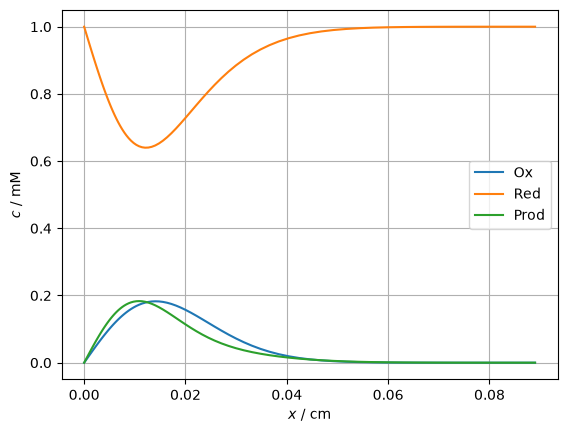

In [3]:
plt.figure()
plt.plot(sim.x * 1e2, sim.concentrations["Ox"][-1, :], label="Ox")
plt.plot(sim.x * 1e2, sim.concentrations["Red"][-1, :], label="Red")
plt.plot(sim.x * 1e2, sim.concentrations["Prod"][-1, :], label="Prod")
plt.xlabel("$x$ / cm")
plt.ylabel("$c$ / mM")
plt.grid()
plt.legend()
plt.show()